# 空间算法 ― spatial 模块

这一章确认 `scipy.spatial` 里的空间算法，内容包括找最近点、用凸包把点群围起来、把空间划分成区域这几类计算。

## 本章要学什么

`scipy.spatial` 里有处理空间数据的类与函数，可以做找邻近点、包围点群、划分空间这样的计算。

- 找最近邻点(`KDTree`、`distance`)
- 凸包(`ConvexHull`)
- 沃罗诺伊图(`Voronoi`)
- 德劳内三角剖分(`Delaunay`)

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import helper.matplotlib
import helper.magics
from scipy import spatial  # 空间算法的模块

## 计算最近邻点

一维上已经排好序的数值，用二分查找就能很快找到与指定值最接近的那个：下面的例子在升序排列的随机数 `x` 里，用 `searchsorted()` 找出最接近 0.5 的值。排序要花 $O(N \log N)$，一次查找花 $O(\log N)$。

In [2]:
x = np.sort(np.random.rand(100))
idx = np.searchsorted(x, 0.5)  # 插入 0.5 的位置
print(x[idx], x[idx - 1])  # 最接近 0.5 的值就是这两个之一

0.5086253622042886 0.48936324927387576


同样的思路在 N 维上也能用：`KDTree` 建立 k-d 树，从而快速找出 N 维空间里的最近邻点。

下面的例子用平面上的 100 个点建立 `KDTree`，再为 `targets` 的每个点找出最近的 3 个点。`query()` 返回距离 `dist` 与编号 `idx`。其中 `dist[i, :]` 是从 `targets[i]` 出发按由近到远排列的距离，`idx[i, :]` 是对应点的编号。

In [3]:
from scipy import spatial

np.random.seed(42)
N = 100
points = np.random.uniform(-1, 1, (N, 2))  # 平面上的 N 个点
kd = spatial.KDTree(points)  # 建立 k-d 树

targets = np.array([(0, 0), (0.5, 0.5), (-0.5, 0.5), (0.5, -0.5), (-0.5, -0.5)])
dist, idx = kd.query(targets, 3)  # 每个点附近的 3 个点
%C dist; idx

                 dist                        idx      
--------------------------------------  --------------
[[0.15188266, 0.21919416, 0.27647793],  [[48, 73, 81],
 [0.09595807, 0.15745334, 0.22855398],   [37, 78, 43],
 [0.05009422, 0.17583445, 0.1807312 ],   [79, 22, 92],
 [0.11180181, 0.16618122, 0.18127473],   [35, 58,  6],
 [0.19015485, 0.19060739, 0.19361173]]   [83,  7, 42]]


`query_ball_point()` 找出与指定点距离在一定范围内的所有点，返回的只有编号；由于每个点附近的点数不同，`idx2` 的每个元素都是一个列表。

In [4]:
r = 0.2
idx2 = kd.query_ball_point(targets, r)  # 半径 r 以内的点
idx2

array([list([48]), list([37, 78]), list([22, 79, 92]), list([6, 35, 58]),
       list([7, 42, 55, 83])], dtype=object)

`query_pairs()` 在 `points` 里找出距离小于指定值的所有点对，返回的是编号对的集合。下面的代码用集合的差，求出距离在 0.08 到 0.1 之间的点对。

In [5]:
idx3 = kd.query_pairs(0.1) - kd.query_pairs(0.08)  # 距离在 0.08〜0.1 的点对
%col 6 idx3

{(1, 46),     (3, 21),     (3, 82),     (3, 95),     (5, 16),     (9, 30),    
 (10, 87),    (11, 42),    (11, 97),    (18, 41),    (29, 74),    (32, 51),   
 (37, 78),    (39, 61),    (41, 61),    (50, 84),    (55, 83),    (73, 81)}   


下图中把 `targets` 的各个点(星号)附近的点用同色的圆点圈了出来：左边是 `query()` 的 3 近邻，中间是 `query_ball_point()` 半径 `r` 以内的点，右边是距离在 0.08 到 0.1 之间的点对。

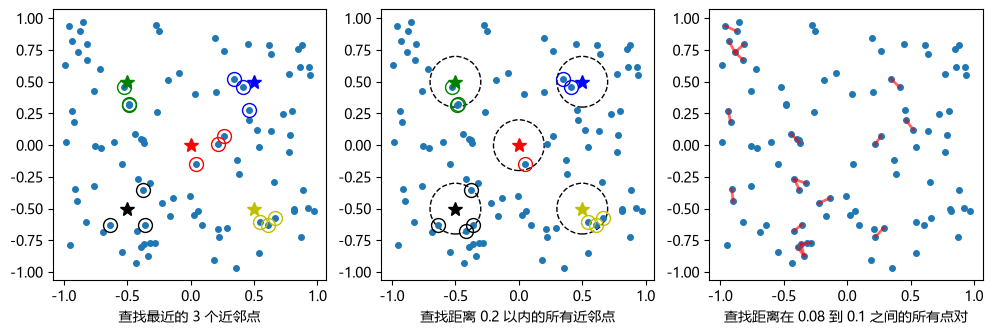

In [6]:
x, y = points.T  # 点的坐标
colors = "r", "b", "g", "y", "k"

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4))

for ax in ax1, ax2, ax3:
    ax.set_aspect("equal")
    ax.plot(x, y, "o", markersize=4)

for ax in ax1, ax2:
    for i in range(len(targets)):
        c = colors[i]
        tx, ty = targets[i]
        ax.plot([tx], [ty], "*", markersize=10, color=c)

for i in range(len(targets)):
    nx, ny = points[idx[i]].T
    ax1.plot(
        nx,
        ny,
        "o",
        markersize=10,
        markerfacecolor="None",
        markeredgecolor=colors[i],
        markeredgewidth=1,
    )

    nx, ny = points[idx2[i]].T
    ax2.plot(
        nx,
        ny,
        "o",
        markersize=10,
        markerfacecolor="None",
        markeredgecolor=colors[i],
        markeredgewidth=1,
    )

    ax2.add_artist(plt.Circle(targets[i], r, fill=None, linestyle="dashed"))

for pidx1, pidx2 in idx3:
    sx, sy = points[pidx1]
    ex, ey = points[pidx2]
    ax3.plot([sx, ex], [sy, ey], "r", linewidth=2, alpha=0.6)

ax1.set_xlabel("查找最近的 3 个近邻点")
ax2.set_xlabel("查找距离 0.2 以内的所有近邻点")
ax3.set_xlabel("查找距离在 0.08 到 0.1 之间的所有点对");

`KDTree` 的查找方法都有一个 `p`，用来决定距离的计算方式，不妨改一改 `p` 看看上图会怎么变。

* `p = 1`：各坐标差绝对值之和(曼哈顿距离)
* `p = 2`：欧氏距离
* `p = np.inf`：各坐标差中的最大值(切比雪夫距离)

`query_ball_tree()` 则在两棵 k-d 树之间找出距离小于指定值的点对。

`distance` 模块的 `pdist()` 计算一个点集内所有两点之间的距离，`cdist()` 计算两个点集之间的距离；由于 `pdist()` 返回的是压成一维的数组，所以用 `squareform()` 还原成二维，其中 `dist1[i, j]` 是 `points` 中 i 与 j 的距离、`dist2[i, j]` 是 `points[i]` 与 `targets[j]` 的距离。

In [7]:
from scipy.spatial import distance

dist1 = distance.squareform(distance.pdist(points))  # 所有两点之间的距离
dist2 = distance.cdist(points, targets)  # points 与 targets 之间的距离
%C dist1.shape; dist2.shape

dist1.shape  dist2.shape
-----------  -----------
(100, 100)   (100, 5)   


用 `np.min()` 取 `dist2` 每一列的最小值，就得到到 `targets` 最近的点之间的距离，结果与 `KDTree.query()` 相同。

In [8]:
print(dist[:, 0])  # KDTree.query() 返回的到 targets 的最近距离
print(np.min(dist2, axis=0))

[0.15188266 0.09595807 0.05009422 0.11180181 0.19015485]
[0.15188266 0.09595807 0.05009422 0.11180181 0.19015485]


要在 `points` 里找出距离最近的两个点，就把 `dist1` 的对角元素设为无穷大之后求最小值。因为对角元素是与自身的距离、等于 0。

In [9]:
dist1[np.diag_indices(len(points))] = np.inf  # 去掉与自身的距离
nearest_pair = np.unravel_index(np.argmin(dist1), dist1.shape)
print(nearest_pair, dist1[nearest_pair])

(np.int64(22), np.int64(92)) 0.005346210248158245


用 `KDTree.query()` 也能找出同一组点：拿 k-d 树自身的点去查询，求出每个点附近最近的 2 个点。其中第 1 个是它自己、距离为 0，第 2 个才是最近邻；再挑出第 2 个距离最小的点，就得到距离最近的那一对。

In [10]:
dist, idx = kd.query(points, 2)  # 自己与最近邻共 2 个点
print(idx[np.argmin(dist[:, 1])], np.min(dist[:, 1]))

[22 92] 0.005346210248158245


## 凸包

凸包是把点群恰好围住的最小凸图形：二维时是凸多边形，三维时是凸多面体。而 `ConvexHull` 计算 N 维点群的凸包。

先看二维的例子：`points2d` 是平面上的点，`ch2d` 是它的凸包。`simplices` 是凸包各条边的两个端点编号，形状为 `(5, 2)`，说明这个凸包由 5 条线段组成；二维时 `vertices` 是凸多边形顶点的编号，按逆时针排列。

In [11]:
np.random.seed(42)
points2d = np.random.rand(10, 2)
ch2d = spatial.ConvexHull(points2d)  # 二维的凸包
%C ch2d.simplices; ch2d.vertices

ch2d.simplices   ch2d.vertices 
--------------  ---------------
[[2, 5],        [5, 2, 6, 1, 0]
 [2, 6],                       
 [0, 5],                       
 [1, 6],                       
 [1, 0]]                       


用 `matplotlib` 的 `Polygon` 可以画出下图的多边形。

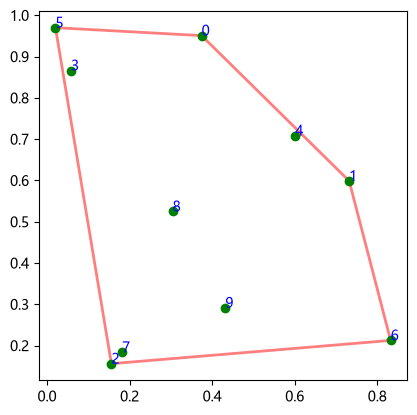

In [12]:
poly = plt.Polygon(points2d[ch2d.vertices], fill=None, lw=2, color="r", alpha=0.5)  # 凸包的多边形
ax = plt.subplot(aspect="equal")
plt.plot(points2d[:, 0], points2d[:, 1], "go")
for i, pos in enumerate(points2d):
    plt.text(pos[0], pos[1], str(i), color="blue")
ax.add_artist(poly);

三维的凸包是凸多面体，它的面是三角形；从 `simplices` 的形状可以看出，这个凸包由 38 个三角形组成。

In [13]:
np.random.seed(42)
points3d = np.random.rand(40, 3)
ch3d = spatial.ConvexHull(points3d)  # 三维的凸包
ch3d.simplices.shape

(38, 3)

下面的程序用 PyVista 画凸包：绿色的球是 `points3d` 的点，红线围出的三角形是凸多面体的面。而没有被红线穿过的点都在凸包内部。

In [14]:
import pyvista as pv
from helper.pyvista import plotter_to_iframe

hull = pv.PolyData.from_regular_faces(ch3d.points, faces=ch3d.simplices)  # 做出凸包的面
points = pv.PolyData(points3d)
sphere = pv.Sphere(radius=0.02, theta_resolution=6, phi_resolution=6)
glyphs = points.glyph(orient=False, scale=False, geom=sphere)
plot = pv.Plotter()  # 准备绘图
plot.add_mesh(glyphs, color="green")
plot.add_mesh(hull, opacity=0.75, line_width=2, edge_color="red", show_edges=True)
plotter_to_iframe(plot)

C:\Users\ruoyu\Documents\notebooks\scipybook\scipybook_cn\helper\pyvista.py:12: PyVistaDeprecationWarning: Plotter.export_vtksz is deprecated. Use plotter.trame.export_vtksz(...) instead. Install via `pip install trame-pyvista`.
  zip_data = plotter.export_vtksz(filename=None)


## 沃罗诺伊图

沃罗诺伊图把空间按母点的个数划分成若干区域，每个区域内的点到该区域的母点最近。

In [15]:
points2d = np.array(
    [
        [0.2, 0.1],
        [0.5, 0.5],
        [0.8, 0.1],
        [0.5, 0.8],
        [0.3, 0.6],
        [0.7, 0.6],
        [0.5, 0.35],
    ]
)
vo = spatial.Voronoi(points2d)  # 计算沃罗诺伊图

%C vo.vertices; vo.regions; vo.ridge_vertices

   vo.vertices          vo.regions     vo.ridge_vertices
------------------  -----------------  -----------------
[[0.5   , 0.045 ],  [[-1, 0, 1],       [[-1, 0],        
 [0.245 , 0.351 ],   [-1, 0, 2],        [0, 1],         
 [0.755 , 0.351 ],   [],                [-1, 1],        
 [0.3375, 0.425 ],   [6, 4, 3, 5],      [0, 2],         
 [0.6625, 0.425 ],   [5, -1, 1, 3],     [-1, 2],        
 [0.45  , 0.65  ],   [4, 2, 0, 1, 3],   [3, 5],         
 [0.55  , 0.65  ]]   [6, -1, 2, 4],     [3, 4],         
                     [6, -1, 5]]        [4, 6],         
                                        [5, 6],         
                                        [1, 3],         
                                        [-1, 5],        
                                        [2, 4],         
                                        [-1, 6]]        


用 `voronoi_plot_2d()` 可以画沃罗诺伊图：左图里青色的小点是母点，红色的大点是 `vertices` 并且标了编号；点线与实线把空间分成 7 个区域。而被点线围住的区域会延伸到无穷远。

`regions` 是区域的列表，每个区域是 `vertices` 编号的列表，含 `-1` 的区域就是无限区域，例如 `[6, 4, 3, 5]` 是中央那个区域。

`ridge_vertices` 是边界线的列表，每条边界线由 `vertices` 的两个编号组成，含 `-1` 的边界线就是图中的点线。

想给区域涂色时，外侧的区域是无限的、没法直接画，只要在外面加上 4 个点把整体围起来，每个母点就都有有限的区域了。右图里黑色的点是母点，而每个区域用离它最近的母点的颜色涂上。

In [16]:
bound = np.array([[-100, -100], [-100, 100], [100, 100], [100, -100]])  # 在外侧包围的 4 个点
vo2 = spatial.Voronoi(np.vstack((points2d, bound)))  # 变成有限的区域

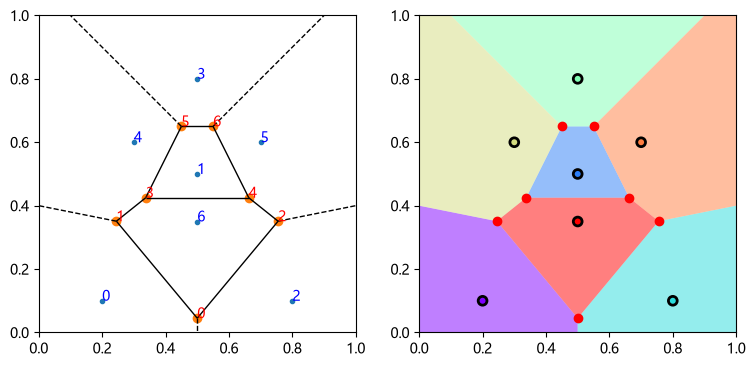

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4.5))
ax1.set_aspect("equal")
ax2.set_aspect("equal")
spatial.voronoi_plot_2d(vo, ax=ax1)  # 画沃罗诺伊图
for i, v in enumerate(vo.vertices):
    ax1.text(v[0], v[1], str(i), color="red")

for i, p in enumerate(points2d):
    ax1.text(p[0], p[1], str(i), color="blue")

n = len(points2d)
color = plt.cm.rainbow(np.linspace(0, 1, n))
for i in range(n):
    idx = vo2.point_region[i]
    region = vo2.regions[idx]
    poly = plt.Polygon(vo2.vertices[region], facecolor=color[i], alpha=0.5, zorder=0)
    ax2.add_artist(poly)
ax2.scatter(points2d[:, 0], points2d[:, 1], s=40, c=color, linewidths=2, edgecolors="k")
ax2.plot(vo2.vertices[:, 0], vo2.vertices[:, 1], "ro", ms=6)

for ax in ax1, ax2:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

沃罗诺伊图还能用来解最大空圆问题：在点群的凸包里，找出一个不包含任何内部点的最大圆。这个圆的圆心一定是某个 `vertices`，半径则是到最近母点的距离。

母点与 `vertices` 的关系可以从 `point_region` 看出来，其中 `point_region[i]` 是母点 `points2d[i]` 所对应的最近区域的编号。下面的输出里，编号 5 的青色点对应区域 6。而由 `regions[6]` 可知该区域由 `vertices` 的 6、2、4 组成(其中的 `-1` 表示无穷远)，也就是说母点 `points2d[5]` 最近的 `vertices` 是 2、4、6 中的一个。

In [18]:
print(vo.point_region)
print(vo.regions[6])

[0 3 1 7 4 6 5]
[6, -1, 2, 4]


下面是计算最大空圆的程序。

❶ 用 `Polygon.contains_point()` 检查 `ConvexHull` 的凸多边形是否包含 `vertices` 中的点，❷ 再把凸包之外的点去掉。

❸ `vertice_point_map` 是一个字典，键为 `vertices` 的编号、值为离该点最近的母点编号；它由 `point_region` 与 `regions` 做出来，凸包之外的点不放进去。

❹ 对字典里的每个点算出到最近母点的距离，取其中最大的一个，就得到圆的圆心与半径。

r =  0.17427845676199402 , center =  [0.46973363 0.59356531]


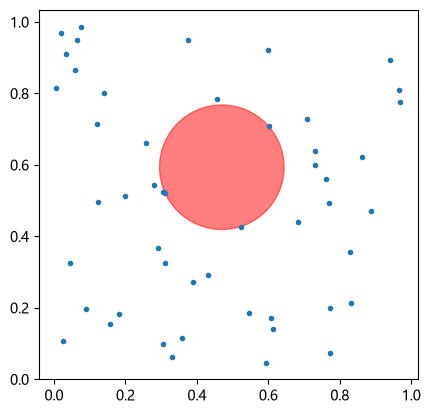

In [19]:
from collections import defaultdict

n = 50
np.random.seed(42)
points2d = np.random.rand(n, 2)
vo = spatial.Voronoi(points2d)
ch = spatial.ConvexHull(points2d)
poly = plt.Polygon(points2d[ch.vertices])  #❶
vs = vo.vertices
convexhull_mask = [poly.contains_point(p, radius=0) for p in vs]  #❷

vertice_point_map = defaultdict(list)  #❸
for index_point, index_region in enumerate(vo.point_region):
    region = vo.regions[index_region]
    if -1 in region:
        continue
    for index_vertice in region:
        if convexhull_mask[index_vertice]:
            vertice_point_map[index_vertice].append(index_point)


def dist(p1, p2):
    return ((p1 - p2) ** 2).sum() ** 0.5


max_cicle = max(
    (dist(points2d[pidxs[0]], vs[vidx]), vs[vidx])  #❹
    for vidx, pidxs in vertice_point_map.items()
)
r, center = max_cicle
print("r = ", r, ", center = ", center)

ax = plt.subplot(111, aspect="equal")
ax.plot(points2d[:, 0], points2d[:, 1], ".")

c = plt.Circle(center, r, fill=True, color="red", alpha=0.5)
ax.add_artist(c);

## 德劳内三角剖分

德劳内三角剖分把点群的凸包划分成三角形，每个三角形的外接圆里都不含其他点。

`Delaunay` 对象 `dy` 的 `simplices` 是各三角形的顶点编号，而外接圆的圆心则可以从同一个点群的沃罗诺伊图的 `vertices` 得到。

In [20]:
x = np.array(
    [
        46.445,
        263.251,
        174.176,
        280.899,
        280.899,
        189.358,
        135.521,
        29.638,
        101.907,
        226.665,
    ]
)
y = np.array(
    [
        287.865,
        250.891,
        287.865,
        160.975,
        54.252,
        160.975,
        232.404,
        179.187,
        35.765,
        71.361,
    ]
)
points2d = np.c_[x, y]
dy = spatial.Delaunay(points2d)  # 三角形分割
vo = spatial.Voronoi(points2d)

%C dy.simplices; vo.vertices

dy.simplices           vo.vertices          
------------  ------------------------------
[[8, 5, 7],   [[104.58977484, 127.03566055],
 [1, 5, 3],    [235.1285    , 198.68143374],
 [5, 6, 7],    [107.83960707, 155.53682482],
 [6, 0, 7],    [ 71.22104881, 228.39479887],
 [0, 6, 2],    [110.3105    , 291.17642838],
 [6, 1, 2],    [201.40695449, 227.68436282],
 [1, 6, 5],    [201.61895891, 226.21958623],
 [9, 5, 8],    [152.96231864,  93.25060083],
 [4, 9, 8],    [205.40381294, -90.5480267 ],
 [5, 9, 3],    [235.1285    , 127.45701644],
 [9, 4, 3]]    [267.91709907, 107.6135    ]]


用 `delaunay_plot_2d()` 画出三角剖分，再画上外接圆，可以看到每个三角形的外接圆里都没有其他点。

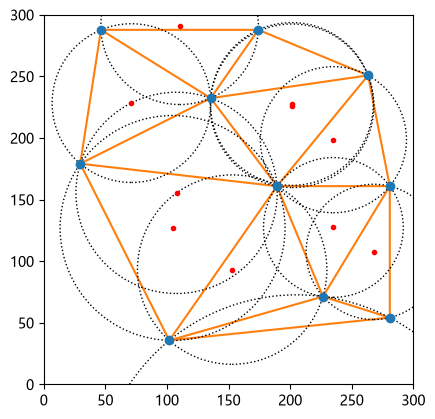

In [21]:
cx, cy = vo.vertices.T

ax = plt.subplot(aspect="equal")
spatial.delaunay_plot_2d(dy, ax=ax)  # 画出三角形
ax.plot(cx, cy, "r.")
for i, (cx, cy) in enumerate(vo.vertices):
    px, py = points2d[dy.simplices[i, 0]]
    radius = np.hypot(cx - px, cy - py)
    circle = plt.Circle((cx, cy), radius, fill=False, ls="dotted")
    ax.add_artist(circle)
ax.set_xlim(0, 300)
ax.set_ylim(0, 300);

## 小结

* 找邻近点用 `KDTree`：`query()` 求 k 近邻，`query_ball_point()` 求半径内的点，`query_pairs()` 求距离相近的点对。
* `distance.pdist()` 与 `cdist()` 可以一次算出所有两点之间的距离。
* 把点群围住的最小凸图形是凸包，用 `ConvexHull` 计算。
* 沃罗诺伊图把空间划分成母点的区域，`regions` 与 `ridge_vertices` 给出区域与边界。
* 德劳内三角剖分的每个三角形，其外接圆里都不含其他点。